In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: grades of six students
data = {
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}

students = ["S1", "S2", "S3", "S4", "S5", "S6"]

df = pd.DataFrame(data, index=students)

print("Original dataset:")
print(df)

Original dataset:
    Mathematics  Statistics  Programming  Algorithms
S1           12          11           14          13
S2           15          14           16          15
S3            8           9           10           9
S4           17          16           18          17
S5           10          12           11          10
S6           14          15           13          14


In [46]:
# Display dataset dimensions
print("Dataset dimensions:", df.shape)

# Display descriptive statistics
print("\nDescriptive statistics:")
print(df.describe())

Dataset dimensions: (6, 4)

Descriptive statistics:
       Mathematics  Statistics  Programming  Algorithms
count     6.000000    6.000000     6.000000     6.00000
mean     12.666667   12.833333    13.666667    13.00000
std       3.326660    2.639444     3.011091     3.03315
min       8.000000    9.000000    10.000000     9.00000
25%      10.500000   11.250000    11.500000    10.75000
50%      13.000000   13.000000    13.500000    13.50000
75%      14.750000   14.750000    15.500000    14.75000
max      17.000000   16.000000    18.000000    17.00000


In [47]:
# Calculate the mean of each subject
mean = df.mean()

# Calculate the population standard deviation
std = df.std(ddof=0)

# Standardize the dataset
Z = (df - mean) / std

print("Means:")
print(mean)

print("\nStandard deviations:")
print(std)

print("\nStandardized data:")
print(Z.round(4))

Means:
Mathematics    12.666667
Statistics     12.833333
Programming    13.666667
Algorithms     13.000000
dtype: float64

Standard deviations:
Mathematics    3.036811
Statistics     2.409472
Programming    2.748737
Algorithms     2.768875
dtype: float64

Standardized data:
    Mathematics  Statistics  Programming  Algorithms
S1      -0.2195     -0.7609       0.1213      0.0000
S2       0.7683      0.4842       0.8489      0.7223
S3      -1.5367     -1.5909      -1.3339     -1.4446
S4       1.4269      1.3143       1.5765      1.4446
S5      -0.8781     -0.3459      -0.9701     -1.0835
S6       0.4391      0.8992      -0.2425      0.3612


In [48]:
# Compute the covariance matrix
cov_matrix = np.cov(Z, rowvar=False)

cov_df = pd.DataFrame(
    cov_matrix,
    index=df.columns,
    columns=df.columns
)

print("Covariance matrix:")
print(cov_df.round(4))

Covariance matrix:
             Mathematics  Statistics  Programming  Algorithms
Mathematics       1.2000      1.1115       1.1341      1.1893
Statistics        1.1115      1.2000       0.9261      1.0492
Programming       1.1341      0.9261       1.2000      1.1562
Algorithms        1.1893      1.0492       1.1562      1.2000


In [28]:
# Compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[1.11254516e-03 2.29405081e-02 2.88274177e-01 4.48767277e+00]

Eigenvectors:
[[ 0.82959445  0.20931345  0.03196839 -0.51666134]
 [-0.24778895 -0.31490117  0.7822181  -0.47704583]
 [-0.12644207 -0.62487999 -0.59216873 -0.49282207]
 [-0.48413436  0.68304475 -0.19091635 -0.5124595 ]]


In [29]:
# Sort eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues:")
print(eigenvalues)

print("\nReordered eigenvectors:")
print(eigenvectors)

Sorted eigenvalues:
[4.48767277e+00 2.88274177e-01 2.29405081e-02 1.11254516e-03]

Reordered eigenvectors:
[[-0.51666134  0.03196839  0.20931345  0.82959445]
 [-0.47704583  0.7822181  -0.31490117 -0.24778895]
 [-0.49282207 -0.59216873 -0.62487999 -0.12644207]
 [-0.5124595  -0.19091635  0.68304475 -0.48413436]]


In [30]:
# Select the two principal components
n_components = 2

principal_components = eigenvectors[:, :n_components]

print("Selected principal components:")
print(principal_components)

Selected principal components:
[[-0.51666134  0.03196839]
 [-0.47704583  0.7822181 ]
 [-0.49282207 -0.59216873]
 [-0.5124595  -0.19091635]]


In [31]:
# Project standardized data onto the two principal components
X_pca = Z.to_numpy() @ principal_components

# Create a DataFrame for the transformed coordinates
pca_df = pd.DataFrame(
    X_pca,
    index=df.index,
    columns=["PC1", "PC2"]
)

print("Students' coordinates in the new space:")
print(pca_df.round(4))

Students' coordinates in the new space:
       PC1     PC2
S1  0.4166 -0.6740
S2 -1.4165 -0.2373
S3  2.9506 -0.2279
S4 -2.8814 -0.1357
S5  1.6520  0.4827
S6 -0.7214  0.7921


In [33]:
# Calculate explained variance ratio
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Display results
variance_df = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Explained variance (%)": explained_variance_ratio * 100,
    "Cumulative variance (%)": cumulative_variance * 100
}, index=["PC1", "PC2", "PC3", "PC4"])

print("Explained variance:")
print(variance_df.round(4))

# Percentage of variance retained by the first two components
retained_variance = cumulative_variance[1] * 100

print(
    f"\nVariance retained by the first two components: "
    f"{retained_variance:.2f}%"
)

Explained variance:
     Eigenvalue  Explained variance (%)  Cumulative variance (%)
PC1      4.4877                 93.4932                  93.4932
PC2      0.2883                  6.0057                  99.4989
PC3      0.0229                  0.4779                  99.9768
PC4      0.0011                  0.0232                 100.0000

Variance retained by the first two components: 99.50%


PARTIE B 

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select the numerical variables
X = df[["Mathematics", "Statistics", "Programming", "Algorithms"]]

# Standardize the data
scaler = StandardScaler()
Z = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
pca.fit(Z)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [18]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(Z)

In [23]:
import pandas as pd

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=["S1", "S2", "S3", "S4", "S5", "S6"]
)

print("Transformed coordinates of the students:")
print(df_pca)

Transformed coordinates of the students:
         PC1       PC2
S1 -0.416636 -0.674008
S2  1.416464 -0.237266
S3 -2.950619 -0.227866
S4  2.881443 -0.135694
S5 -1.652021  0.482733
S6  0.721369  0.792100


In [34]:
import numpy as np

# Explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Explained variance ratio:")
print(explained_variance_ratio)

print("\nExplained variance ratio in percentage:")
print(explained_variance_ratio * 100)

print("\nCumulative explained variance:")
print(cumulative_variance)

print("\nCumulative explained variance in percentage:")
print(cumulative_variance * 100)

Explained variance ratio:
[0.93493183 0.06005712]

Explained variance ratio in percentage:
[93.4931827   6.00571202]

Cumulative explained variance:
[0.93493183 0.99498895]

Cumulative explained variance in percentage:
[93.4931827  99.49889472]


Part C

In [37]:
import numpy as np

# 1. Calculate the correlation matrix
R = np.corrcoef(Z, rowvar=False)

# 2. Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(R)

# 3. Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[idx]
eigenvectors_sorted = eigenvectors[:, idx]

# 4. Select the first two principal components
W = eigenvectors_sorted[:, :2]

# 5. Calculate the coordinates of the students
X_pca_manual = Z @ W

print("Manual PCA coordinates:")
print(X_pca_manual)

Manual PCA coordinates:
           0         1
S1  0.416636 -0.674008
S2 -1.416464 -0.237266
S3  2.950619 -0.227866
S4 -2.881443 -0.135694
S5  1.652021  0.482733
S6 -0.721369  0.792100


In [38]:
import numpy as np
import pandas as pd

# Manual PCA: eigenvalues sorted in descending order
# Replace eigenvalues_sorted with your variable name from Part A
eigenvalues_manual = eigenvalues_sorted

# Explained variance ratios for manual PCA
ratio_manual = eigenvalues_manual / np.sum(eigenvalues_manual)

# Scikit-learn results
eigenvalues_sklearn = pca.explained_variance_
ratio_sklearn = pca.explained_variance_ratio_

# Compare the results
comparison = pd.DataFrame({
    "Manual eigenvalues": eigenvalues_manual[:2],
    "Scikit-learn eigenvalues": eigenvalues_sklearn[:2],
    "Manual variance ratio": ratio_manual[:2],
    "Scikit-learn variance ratio": ratio_sklearn[:2]
}, index=["PC1", "PC2"])

print("Comparison of eigenvalues and explained variance ratios:")
print(comparison)

Comparison of eigenvalues and explained variance ratios:
     Manual eigenvalues  Scikit-learn eigenvalues  Manual variance ratio  \
PC1            3.739727                  4.487673               0.934932   
PC2            0.240228                  0.288274               0.060057   

     Scikit-learn variance ratio  
PC1                     0.934932  
PC2                     0.060057  


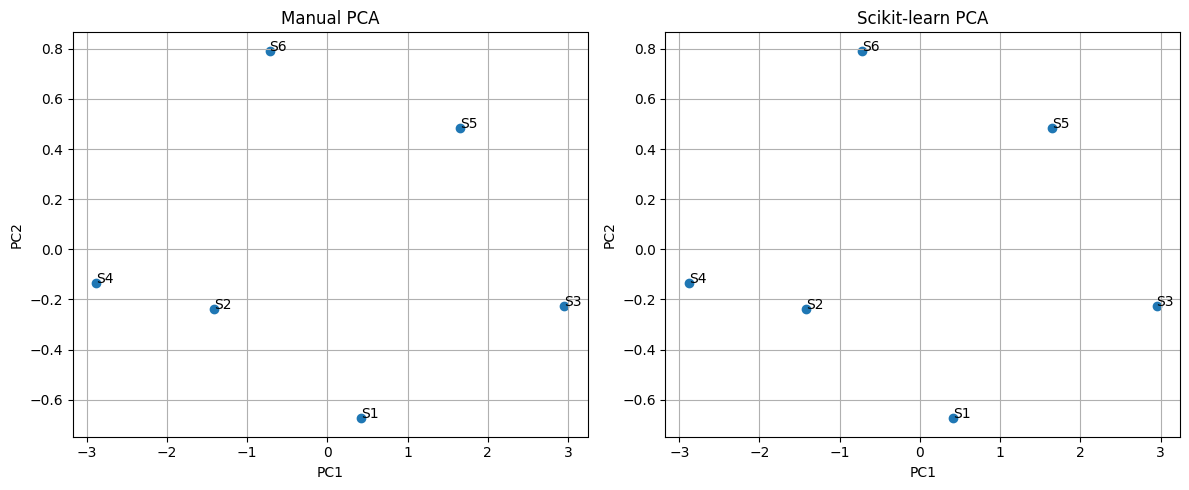

In [42]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

students = ["S1", "S2", "S3", "S4", "S5", "S6"]

# Convert DataFrames to NumPy arrays if necessary
X_manual = np.asarray(X_pca_manual)
X_sklearn = np.asarray(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Manual PCA
axes[0].scatter(X_manual[:, 0], X_manual[:, 1])

for i, student in enumerate(students):
    axes[0].annotate(
        student,
        (X_manual[i, 0], X_manual[i, 1])
    )

axes[0].set_title("Manual PCA")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].grid(True)

# Plot 2: Scikit-learn PCA
axes[1].scatter(X_sklearn[:, 0], X_sklearn[:, 1])

for i, student in enumerate(students):
    axes[1].annotate(
        student,
        (X_sklearn[i, 0], X_sklearn[i, 1])
    )

axes[1].set_title("Scikit-learn PCA")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].grid(True)

plt.tight_layout()

# Create the figures folder if it does not exist
Path("figures").mkdir(exist_ok=True)

plt.savefig("figures/pca_comparison.png", dpi=300)
plt.show()

The manual PCA implementation and the Scikit-learn implementation should produce similar principal component coordinates and explained variance ratios. Small differences may occur because of numerical precision and variance normalization conventions.

The principal component eigenvectors may also have opposite signs. For example, PC1 coordinates from one implementation may be the negatives of those from the other implementation. This sign change does not affect the PCA results: the direction of an eigenvector can be reversed without changing the information it represents. Therefore, the relative positions and distances between students remain equivalent, provided the corresponding axes are compared consistently.

In [40]:
# Total variance explained by the first two components
variance_retained = np.sum(pca.explained_variance_ratio_) * 100

print(
    "Percentage of total variance retained by the first two components:",
    round(variance_retained, 2),
    "%"
)

Percentage of total variance retained by the first two components: 99.5 %
